In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

2
94


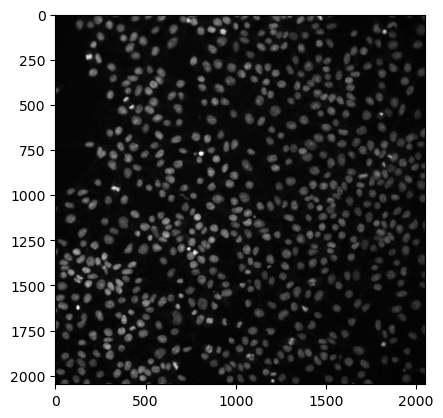

In [2]:
# Cargar imagen
pathtoimage = "img1_rgba.tif" # "Imagen_binaria.jpg"
img_gray = cv.imread(pathtoimage, 0)

plt.imshow(img_gray,cmap = "gray")

print(np.amin(img_gray))
print(np.amax(img_gray)) 

#unique_vals = np.unique(img_gray)
#print("Unique values:", unique_vals)

#hist_0 = cv.calcHist([img_gray], [0], None, [10], [0,256])
#plt.plot(hist_0)
#plt.plot(img_binaria.ravel(), color='black')

Unique values: [  0 255]


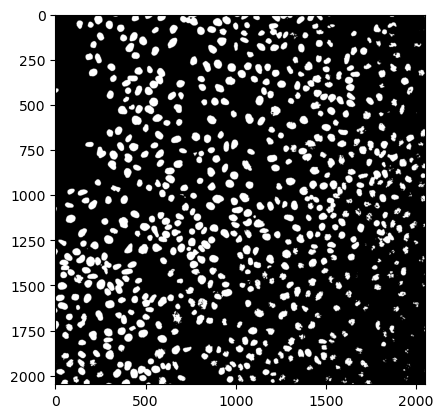

In [3]:
# Versión binaria (para ver el efecto 'clásico' de morfología)
_, img_bin = cv.threshold(img_gray, 20, 255, cv.THRESH_BINARY) #UMBRAL 20. Por debajo es negro por encima blanco
plt.imshow(img_bin, cmap="gray",vmin = 0, vmax = 1)
unique_vals = np.unique(img_bin)
print("Unique values:", unique_vals)



234


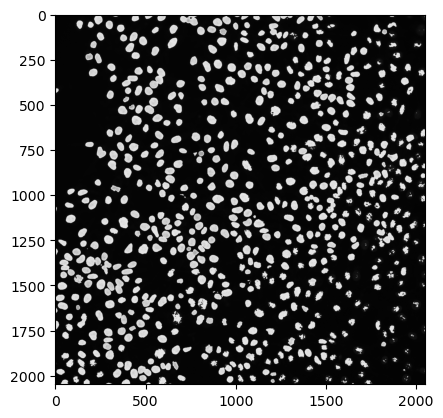

In [7]:
plt.imshow(cv.absdiff(img_bin,img_gray), cmap="gray",vmin = 0, vmax = 255)
print(np.amax(cv.absdiff(img_bin,img_gray))) #no

In [5]:
# Cómo definir el elemento estructurante (SE)

# Opción A: con getStructuringElement (formas predefinidas): llamamos a elementos estructurales predefinidos
se_cuadrado    = cv.getStructuringElement(cv.MORPH_RECT,    (5,5))   # cuadrado 5x5 o rectangulo con 7x5 (cols,filas)
se_elipse = cv.getStructuringElement(cv.MORPH_ELLIPSE, (11,11))   # disco aprox 5x5
se_cruz   = cv.getStructuringElement(cv.MORPH_CROSS,   (5,5))   # cruz 5x5 anchoxlargo

# Opción B: kernel personalizado (np.uint8 con 0/1)
se_orig = np.array([[0,1,0],
                    [1,1,1],
                    [0,1,0]], dtype=np.uint8)  # cruz 3x3

# Para cambiar el SE en los ejercicios: se_cuadrado, se_elipse, se_cruz, se_orig
SE = se_cuadrado


In [11]:
se_elipse

array([[0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0],
       [0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0],
       [0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0],
       [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
       [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
       [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
       [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
       [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
       [0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0],
       [0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0],
       [0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0]], dtype=uint8)

## Dilatación

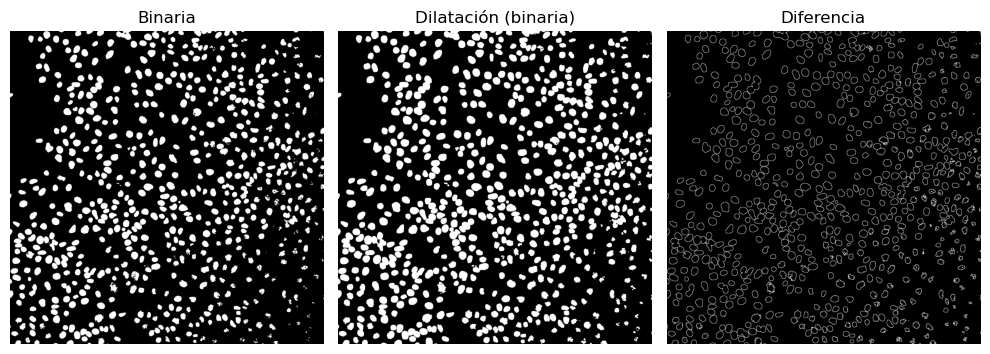

In [10]:
# Dilatación en binaria
dil_bin = cv.dilate(img_bin, SE, iterations=1) #iteraciones: 2 iteraciones: dilatar sobre lo dilatado
difdil = cv.absdiff(img_bin,dil_bin)

#Los elementos base (los puntitos blancos) tienen forma de elipse
# Visualizar
plt.figure(figsize=(10,6))
plt.subplot(1,3,1); plt.imshow(img_bin,  cmap='gray'); plt.title('Binaria');   plt.axis('off')
plt.subplot(1,3,2); plt.imshow(dil_bin,  cmap='gray'); plt.title('Dilatación (binaria)'); plt.axis('off')
plt.subplot(1,3,3); plt.imshow(difdil,  cmap='gray'); plt.title('Diferencia'); plt.axis('off')
plt.tight_layout(); plt.show()

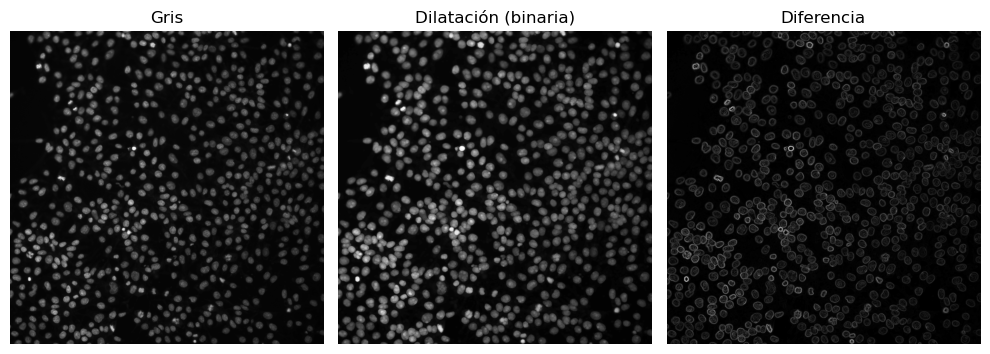

In [15]:
# Dilatación en binaria PARA ESCALA DE GRISES
dil_gray = cv.dilate(img_gray, SE, iterations=1)
difdilgray = cv.absdiff(img_gray,dil_gray)

# Visualizar
plt.figure(figsize=(10,6))
plt.subplot(1,3,1); plt.imshow(img_gray,  cmap='gray'); plt.title('Gris');   plt.axis('off')
plt.subplot(1,3,2); plt.imshow(dil_gray,  cmap='gray'); plt.title('Dilatación (binaria)'); plt.axis('off')
plt.subplot(1,3,3); plt.imshow(difdilgray,  cmap='gray'); plt.title('Diferencia'); plt.axis('off')
plt.tight_layout(); plt.show()

## Erosión

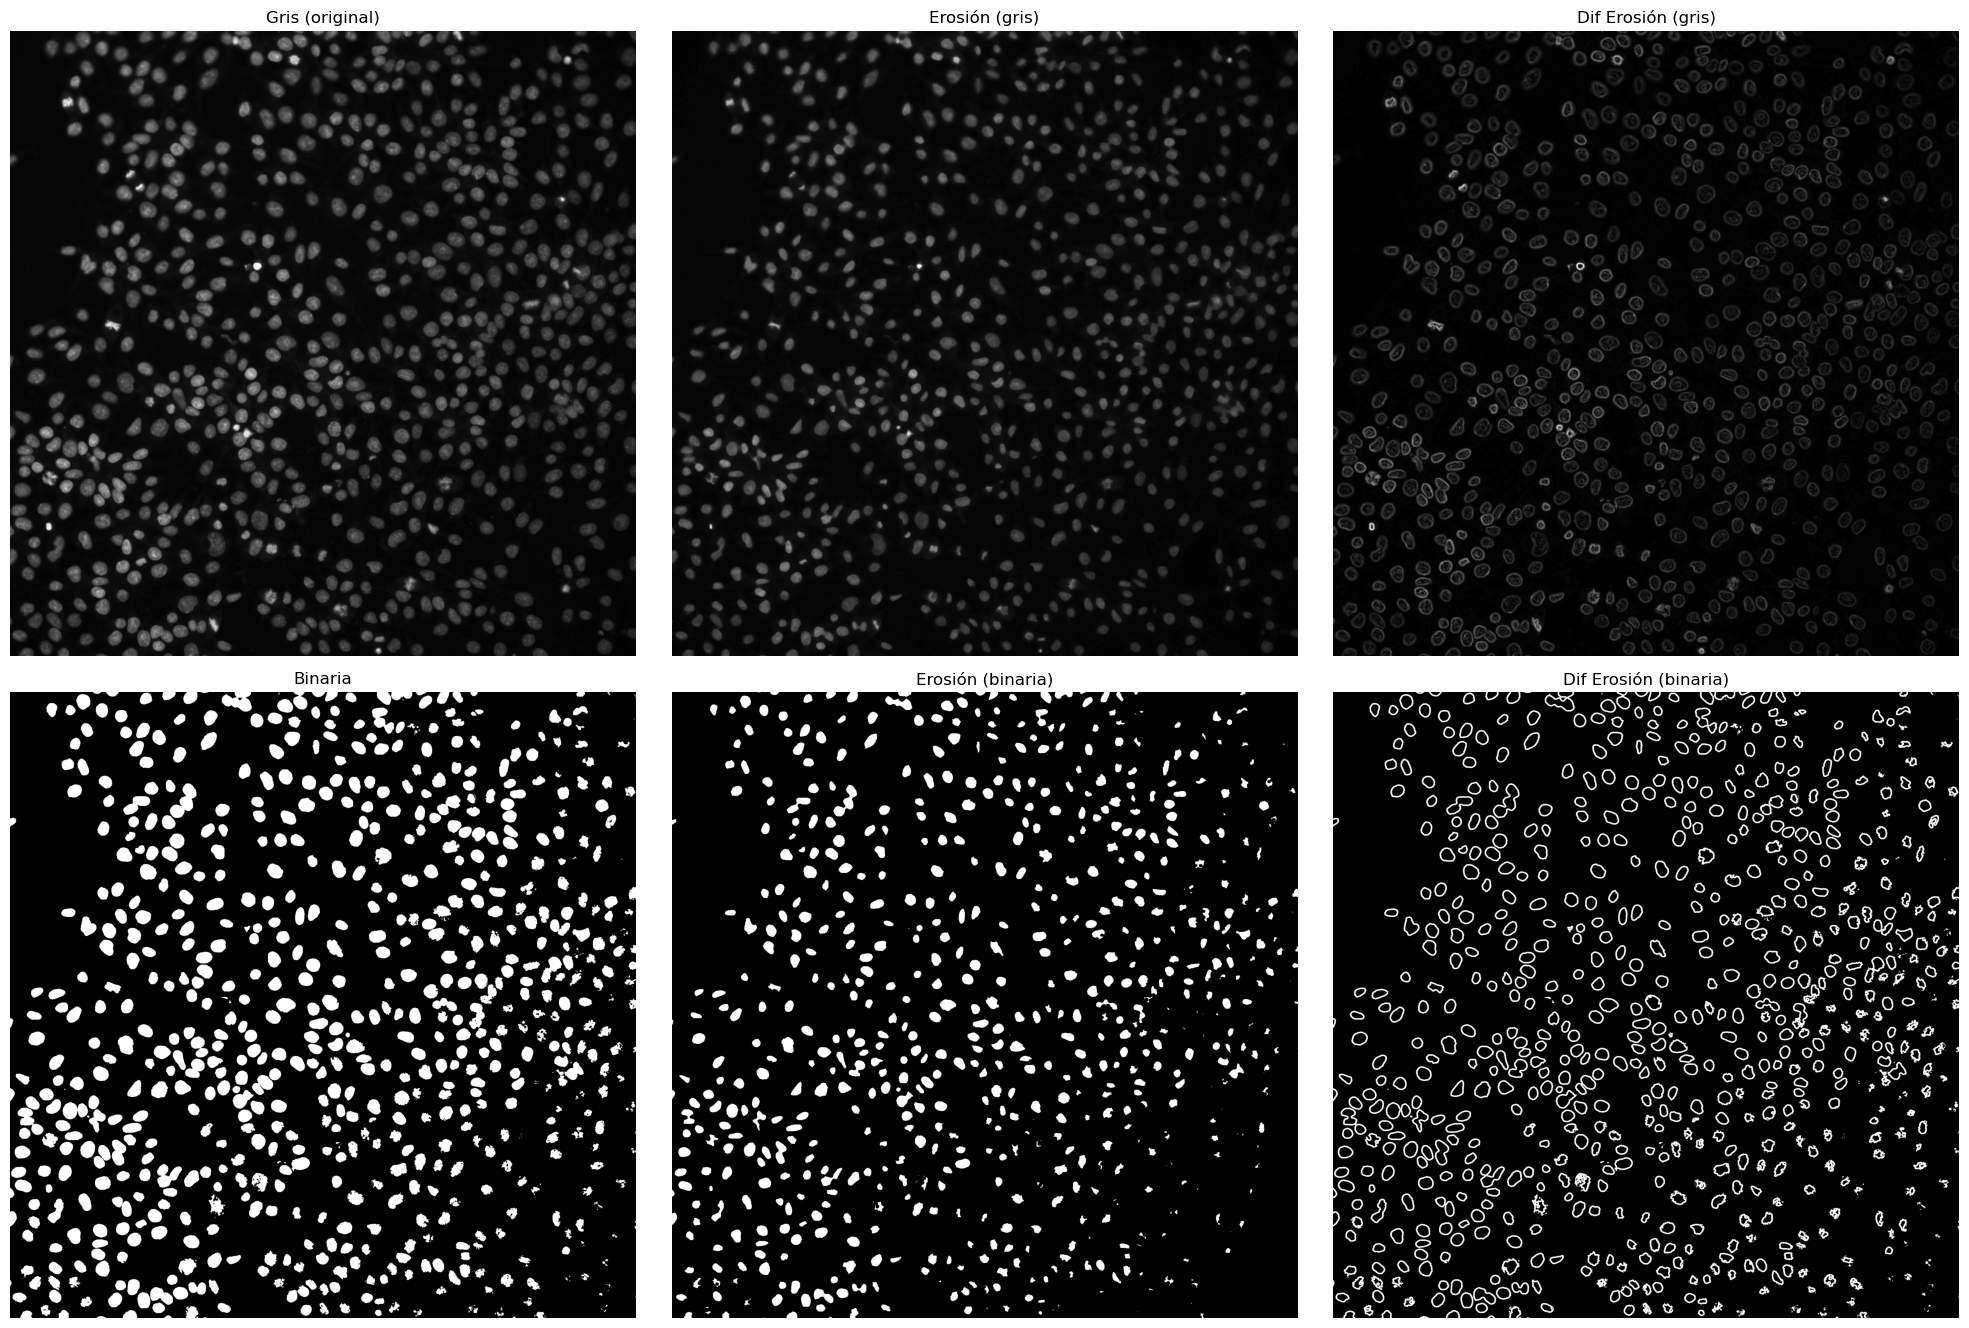

In [17]:
# Erosión en binaria
ero_bin = cv.erode(img_bin, SE, iterations=1)
diferobin = cv.absdiff(img_bin, ero_bin)

# Erosión en escala de grises LO MISMO Q FILTRO DE MIN
ero_gray = cv.erode(img_gray, SE, iterations=1)
diferogris = cv.absdiff(img_gray, ero_gray)

# Visualizar
plt.figure(figsize=(20,20))
plt.subplot(3,3,1); plt.imshow(img_gray, cmap='gray'); plt.title('Gris (original)'); plt.axis('off')
plt.subplot(3,3,2); plt.imshow(ero_gray, cmap='gray'); plt.title('Erosión (gris)');  plt.axis('off')
plt.subplot(3,3,3); plt.imshow(diferogris, cmap='gray'); plt.title('Dif Erosión (gris)');  plt.axis('off')

plt.subplot(3,3,4); plt.imshow(img_bin,  cmap='gray'); plt.title('Binaria');   plt.axis('off')
plt.subplot(3,3,5); plt.imshow(ero_bin,  cmap='gray'); plt.title('Erosión (binaria)'); plt.axis('off')
plt.subplot(3,3,6); plt.imshow(diferobin, cmap='gray'); plt.title('Dif Erosión (binaria)');  plt.axis('off')

plt.tight_layout(); plt.show()


## Apertura

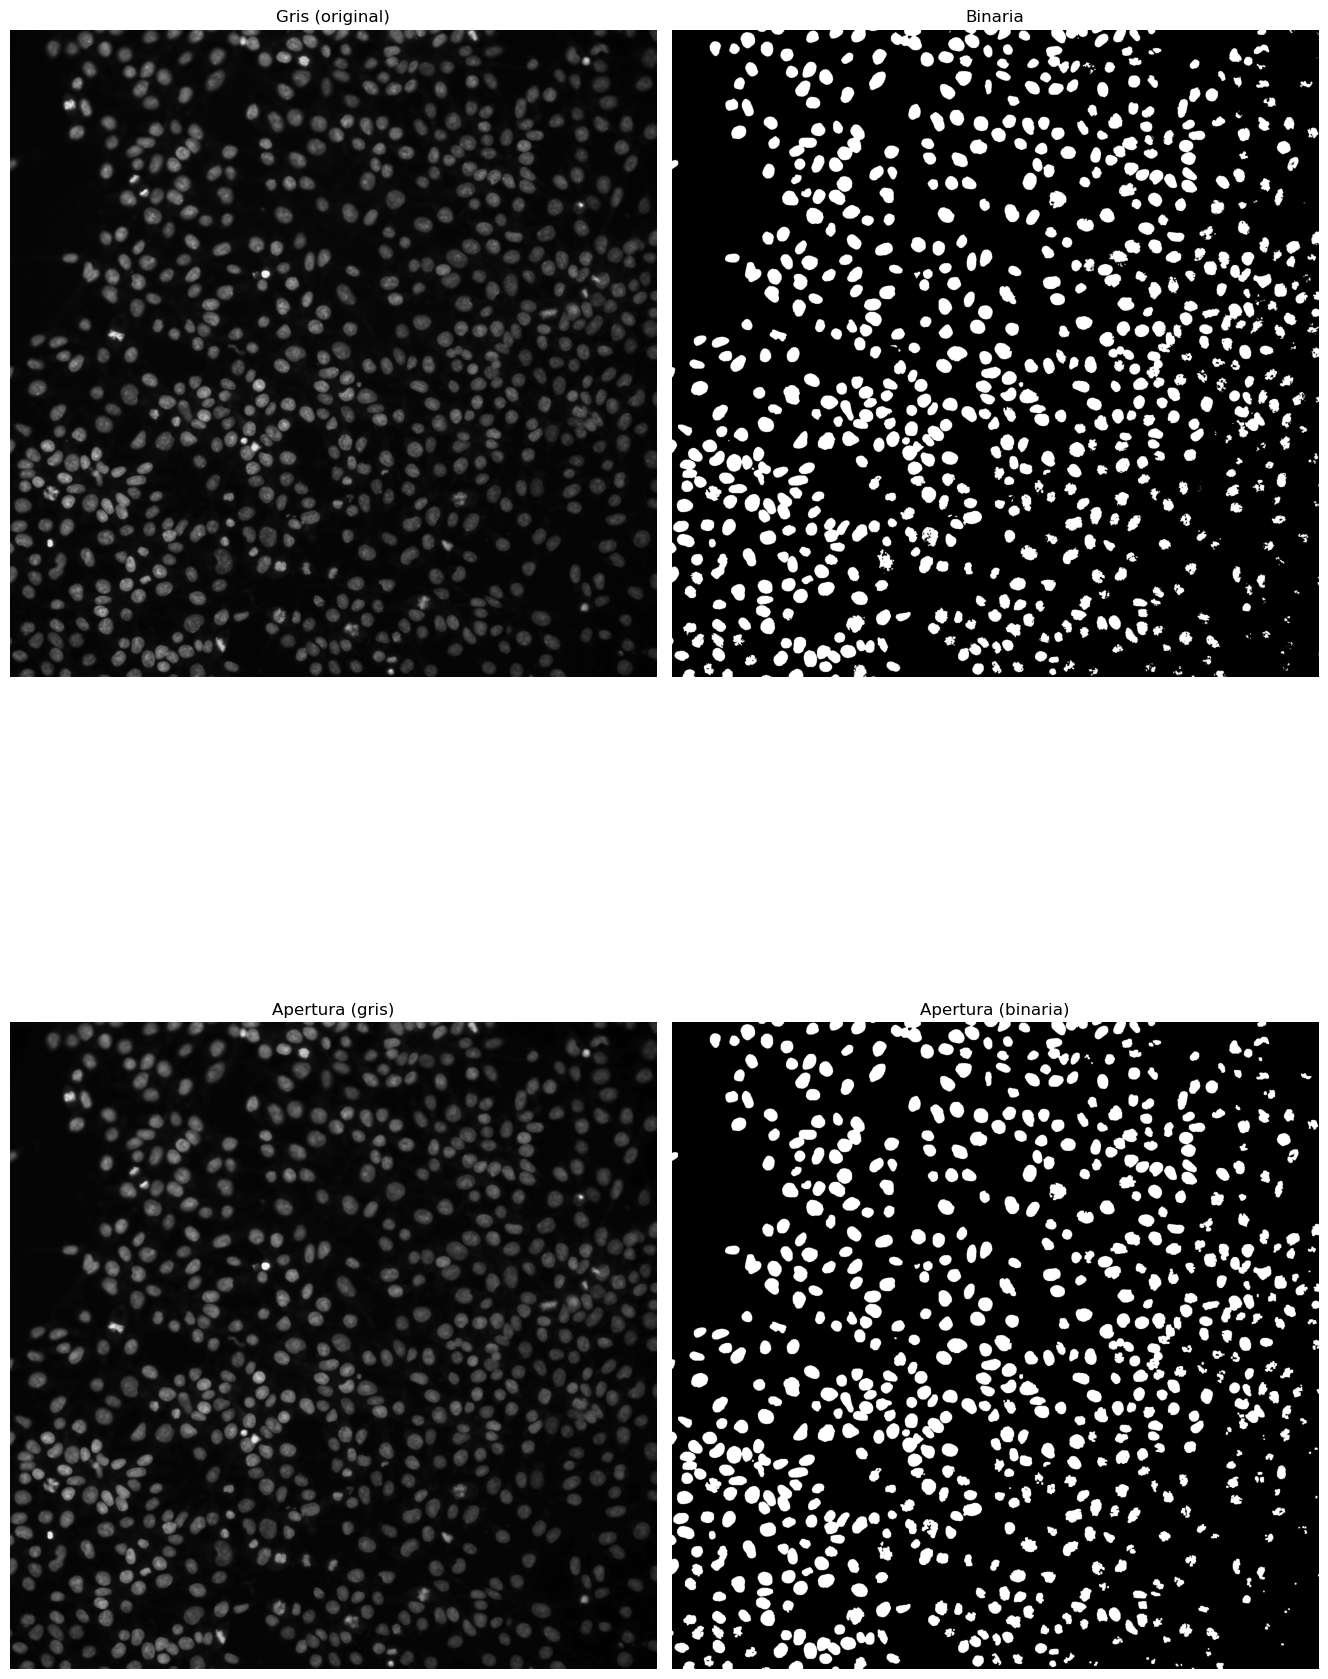

In [12]:
# Apertura en binaria (EROSIONA Y LUEGO DILATA) ROMPER TROCITOS PEQUEÑOS Q ESTAN UNIDOS
open_bin = cv.morphologyEx(img_bin,  cv.MORPH_OPEN, SE, iterations=1)

# Apertura en grises (min seguido de max)
open_gray = cv.morphologyEx(img_gray, cv.MORPH_OPEN, SE, iterations=1)

# Visualizar
plt.figure(figsize=(20,20))
plt.subplot(2,3,1); plt.imshow(img_gray, cmap='gray'); plt.title('Gris (original)'); plt.axis('off')
plt.subplot(2,3,2); plt.imshow(img_bin,  cmap='gray'); plt.title('Binaria');   plt.axis('off')
plt.subplot(2,3,4); plt.imshow(open_gray, cmap='gray'); plt.title('Apertura (gris)'); plt.axis('off')
plt.subplot(2,3,5); plt.imshow(open_bin,  cmap='gray'); plt.title('Apertura (binaria)'); plt.axis('off')
plt.tight_layout(); plt.show()


## Clausura

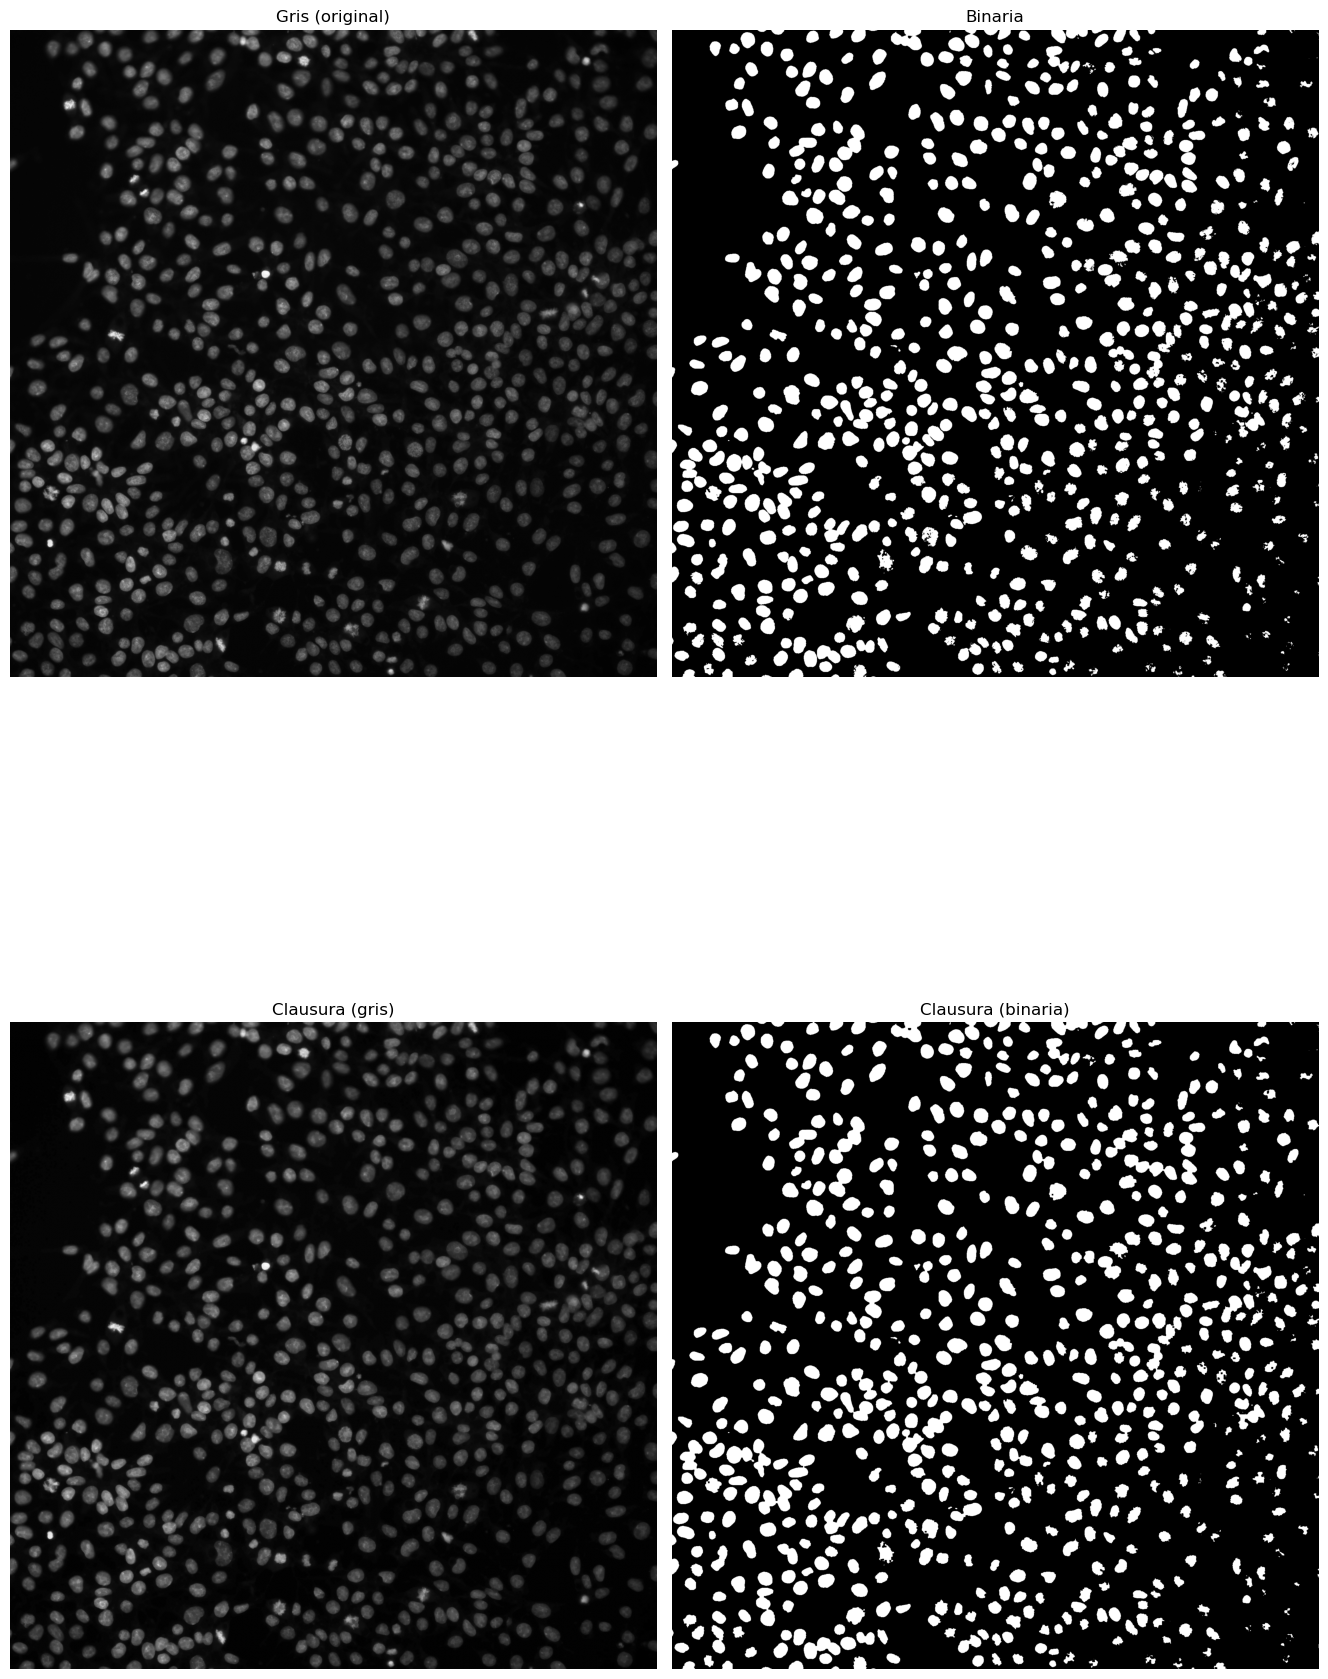

In [14]:
# Apertura en binaria (DILATA Y LUEGO EROSIONA) SI SE ME QUEDA UN HUECO QUE QUIERO CERRAR
open_bin = cv.morphologyEx(img_bin,  cv.MORPH_CLOSE, SE, iterations=1)

# Apertura en grises (min seguido de max)
open_gray = cv.morphologyEx(img_gray, cv.MORPH_CLOSE, SE, iterations=1)

# Visualizar
plt.figure(figsize=(20,20))
plt.subplot(2,3,1); plt.imshow(img_gray, cmap='gray'); plt.title('Gris (original)'); plt.axis('off')
plt.subplot(2,3,2); plt.imshow(img_bin,  cmap='gray'); plt.title('Binaria');   plt.axis('off')
plt.subplot(2,3,4); plt.imshow(open_gray, cmap='gray'); plt.title('Clausura (gris)'); plt.axis('off')
plt.subplot(2,3,5); plt.imshow(open_bin,  cmap='gray'); plt.title('Clausura (binaria)'); plt.axis('off')
plt.tight_layout(); plt.show()